In [1]:
import jax.numpy as jnp, numpy as np
import matplotlib.pyplot as plt
import gebtaero_jax as gx

I11 = 8.64
cs = gx.CrossSection.from_isotropic(9.77e6, 0.0, 0.99e6).with_mass(35.71, 1e-4 * I11, I11, 0.0, 0.18288)
goland = gx.straight_wing(cs, 6.096, 1.8288, -0.34, 10, aero=gx.Aero.PETERS)
pf = gx.flutter_speed(goland, gx.FlightCondition(rho=1.225), 100, 160, n_grid=7)
print(pf)

def tip_pulse(t, fl):
    return fl.replace(tip_force=jnp.array([0.0, 0.0, -jnp.where(t < 0.02, 2000.0, 0.0)]))

CriticalPoint(flutter: V=136.5067 m/s, f=11.1914 Hz)


## Below and above the flutter speed (GEBTAero `TemporalFlutterSpeed` / `FlutterVtk`)

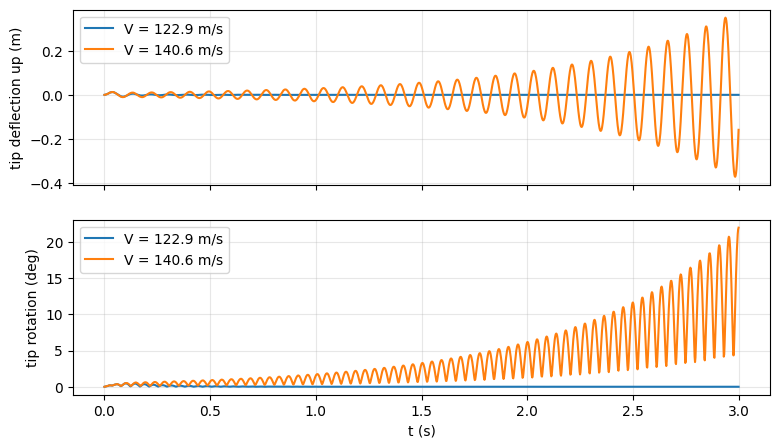

In [2]:
fig, axs = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for V in [0.9 * pf.velocity, 1.03 * pf.velocity]:
    fl = gx.FlightCondition(velocity=V, rho=1.225)
    h = gx.simulate(goland, fl, t_end=3.0, dt=0.002, flight_fn=tip_pulse)
    axs[0].plot(h.t, -h.tip()[:, 2], label=f"V = {V:.1f} m/s")
    axs[1].plot(h.t, np.degrees(gx.rotations.rodrigues_to_angle(jnp.asarray(h.tip()[:, 3:]))), label=f"V = {V:.1f} m/s")
axs[0].set_ylabel("tip deflection up (m)"); axs[1].set_ylabel("tip rotation (deg)"); axs[1].set_xlabel("t (s)")
for ax in axs: ax.grid(alpha=.3); ax.legend()

## Consistency with the modal analysis
The exponential growth rate of the tip response matches Re(s) of the critical eigenvalue.

In [3]:
V = 140.0
fl = gx.FlightCondition(velocity=V, rho=1.225)
res = gx.modal_analysis(goland, fl)
sigma = res.eigvals.real[res.oscillatory()].max()
h = gx.simulate(goland, fl, 3.0, 0.002, flight_fn=tip_pulse)
tw = h.tip_rotation_angle()
pk = [i for i in range(1, len(tw) - 1) if tw[i] > tw[i - 1] and tw[i] >= tw[i + 1] and h.t[i] > 1.0]
rate = np.polyfit(h.t[pk], np.log(tw[pk]), 1)[0]
print(f"modal Re(s) = {sigma:.4f} 1/s,  time-domain growth = {rate:.4f} 1/s")

modal Re(s) = 1.0959 1/s,  time-domain growth = 1.0900 1/s


## Gust response of the Patil wing
A "1 − cos" vertical gust is imposed through the velocity of frame *a* (`v_a`, z_a points down so a negative
value is an up-gust seen by the wing). The wing first settles under gravity and aerodynamic load at 25 m/s,
α = 2°; the simulation then starts from that nonlinear equilibrium.

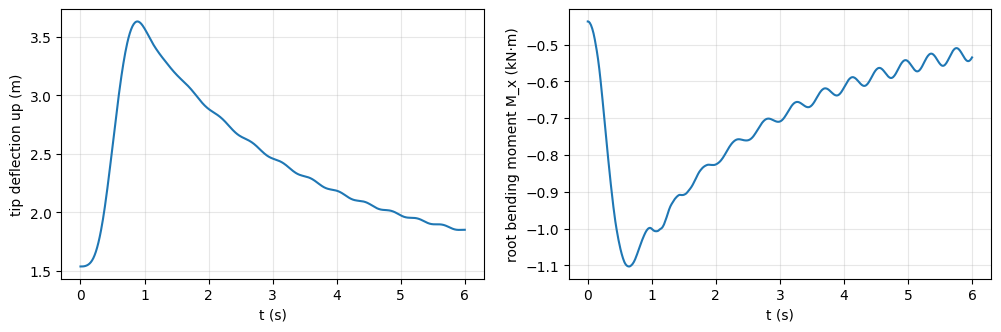

In [4]:
csP = gx.CrossSection.from_isotropic(2e4, 4e6, 1e4).with_mass(0.75, 0.0375, 0.0625)
patil = gx.straight_wing(csP, 16.0, 1.0, 0.0, 10, aero=gx.Aero.PETERS, damping=jnp.full(6, 1e-4))
flP = gx.FlightCondition(velocity=25.0, rho=0.0889, alpha=np.radians(2.0), gravity=9.81)
x0 = gx.solve_static(patil, flP, n_load_steps=4)

def gust(t, fl, w0=3.0, T=1.0):
    w = jnp.where(t < T, 0.5 * w0 * (1 - jnp.cos(2 * jnp.pi * t / T)), 0.0)
    return fl.replace(v_a=jnp.array([0.0, 0.0, w]))

h = gx.simulate(patil, flP, t_end=6.0, dt=0.01, x0=x0, flight_fn=gust)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(h.t, -h.tip()[:, 2]); ax[0].set_xlabel("t (s)"); ax[0].set_ylabel("tip deflection up (m)"); ax[0].grid(alpha=.3)
F = np.array([gx.split_state(patil, jnp.asarray(xx))[0][3] for xx in h.x])
ax[1].plot(h.t, F / 1e3); ax[1].set_xlabel("t (s)"); ax[1].set_ylabel("root bending moment M_x (kN·m)"); ax[1].grid(alpha=.3);